In [22]:
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import root_mean_squared_error

In [23]:
df_epi_raw = pd.read_csv('data/epi_r.csv', sep=',')
df_epi_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 20052 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(679), str(1)
memory usage: 104.0 MB


## Duplicates


In [24]:
df_epi_raw.duplicated().sum()

np.int64(1801)

In [25]:
df_epi_drop_dup = df_epi_raw.drop_duplicates()

## DownCast 

In [26]:
(df_epi_drop_dup.nunique()).value_counts()

2        674
17736      1
8          1
1858       1
282        1
326        1
2434       1
Name: count, dtype: int64

Т.е. 674 столбцы имеют 2 униткальных значения, 1 столбец - 17736, 1 - 8 уникальных значений.

Найдем столбцы с 2 уникальными значениями.

In [27]:
mask_cols_eq2 = df_epi_drop_dup.nunique() == 2
cols_eq2 = df_epi_drop_dup.columns[mask_cols_eq2]

In [28]:
df_epi_drop_dup.columns[~mask_cols_eq2]

Index(['title', 'rating', 'calories', 'protein', 'fat', 'sodium'], dtype='str')

In [29]:
df_epi_drop_dup.info(memory_usage=True)

<class 'pandas.DataFrame'>
Index: 18251 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(679), str(1)
memory usage: 94.8 MB


In [30]:
df_epi = df_epi_drop_dup.copy()

In [31]:
for column in df_epi_drop_dup.columns[mask_cols_eq2]:
    df_epi[column] = pd.to_numeric(df_epi[column], downcast='integer')

In [32]:
df_epi.info(memory_usage=True)

<class 'pandas.DataFrame'>
Index: 18251 entries, 0 to 20051
Columns: 680 entries, title to turkey
dtypes: float64(5), int8(674), str(1)
memory usage: 12.7 MB


## Columns filter

Check:
    - frequencies (kiwi not pass)
    - correlation with other columns
    - parcers (ingredient_slicer, pyfood)

In [33]:
import pandas as pd
import re


class StrictIngredientSelector:
    def __init__(self):
        # 1. Список чистых кулинарных корней (только существительные-продукты)
        # fmt: off
        food_words = [
            'almond', 'amaretto', 'anchovy', 'anise', 'apple', 'apricot', 'artichoke', 'arugula', 'pear', 'asparagus',
            'avocado', 'bacon', 'banana', 'barley', 'basil', 'bean', 'beef', 'beer', 'beet', 'berry', 'biscuit', 
            'bitters', 'blackberry', 'blueberry', 'bok choy', 'bourbon', 'bran', 'brandy', 'bread', 'breadcrumbs', 
            'brie', 'brisket', 'broccoli', 'brussel sprout', 'butter', 'buttermilk', 'squash', 'cabbage', 'cake', 
            'calvados', 'campari', 'candy', 'cantaloupe', 'capers', 'caraway', 'cardamom', 'carrot', 'cashew', 
            'cauliflower', 'caviar', 'celery', 'champagne', 'chard', 'chartreuse', 'cheddar', 'cheese', 'cherry', 
            'chestnut', 'chicken', 'chickpea', 'chile', 'chili', 'chocolate', 'cinnamon', 'citrus', 'clam', 'clove', 
            'coconut', 'cod', 'coffee', 'coriander', 'corn', 'cornmeal', 'couscous', 'crab', 'cranberry', 'cream', 
            'cucumber', 'cumin', 'currant', 'curry', 'custard', 'dairy', 'date', 'dill', 'duck', 
            'egg', 'eggplant', 'endive', 'escarole', 'fennel', 'feta', 'fig', 'fish', 'fontina', 'frangelico', 'fruit', 
            'garlic', 'ginger', 'gin', 'goat cheese', 'goose', 'gouda', 'grains', 'grape', 'grapefruit', 
            'grappa', 'green bean', 'onion', 'scallion', 'guava', 'halibut', 'ham', 'hazelnut', 
            'honey', 'honeydew', 'horseradish', 'hummus', 'ice cream', 'jalapeño', 'jam', 'jelly', 'jícama', 'kahlúa', 
            'kale', 'kiwi', 'kumquat', 'lamb', 'leek', 'legume', 'lemon', 'lemongrass', 'lentil', 'lettuce', 
            'lime', 'lingonberry', 'liqueur', 'lobster', 'lychee', 'macadamia', 'mango', 'maple syrup', 'margarita', 
            'marsala', 'marscarpone', 'marshmallow', 'martini', 'mayonnaise', 'meat', 'melon', 'mezcal', 'milk', 
            'mint', 'molasses', 'monterey jack', 'mozzarella', 'muffin', 'mushroom', 'mussel', 'mustard', 'nectarine', 
            'noodle', 'nut', 'nutmeg', 'oat', 'oatmeal', 'octopus', 'okra', 'olive', 'orange', 'oregano', 
            'orzo', 'oyster', 'pancake', 'papaya', 'paprika', 'parmesan', 'parsley', 'parsnip', 'pasta', 'pastry', 
            'pea', 'peach', 'peanut', 'pecan', 'pepper', 'pernod', 'persimmon', 'pickles', 'pine nut', 
            'pineapple', 'pistachio', 'plantain', 'plum', 'poblano', 'pomegranate', 'poppy', 'pork', 
            'port', 'potato', 'poultry', 'prosciutto', 'prune', 'pumpkin', 'punch', 'quail', 'quince', 
            'quinoa', 'rabbit', 'radicchio', 'radish', 'raisin', 'ramekin', 'raspberry', 'red wine', 'rhubarb', 
            'rice', 'ricotta', 'rosemary', 'rosé', 'rum', 'rutabaga', 'rye', 'saffron', 'sage', 'sake', 'salad', 
            'salmon', 'salsa', 'sangria', 'sardine', 'sausage', 'scallop', 'scotch', 
            'semolina', 'sesame', 'shallot', 'shellfish', 'sherry', 'shrimp', 'snapper', 'soufflé', 
            'stew', 'sour cream', 'soy', 'soy sauce', 'sparkling wine', 'spice', 'spinach', 
            'squid', 'steak', 'stock', 'strawberry', 'sweet potato', 'swiss cheese', 'taco', 
            'tamarind', 'tangerine', 'tapioca', 'tart', 'tea', 'tequila', 'thyme', 'tilapia', 'tofu', 'tomatillo', 
            'tomato', 'tortillas', 'triple sec', 'trout', 'tuna', 'turkey', 'turnip', 'vanilla', 'veal', 
            'venison', 'vermouth', 'vinegar', 'vodka', 'walnut', 'wasabi', 'watercress', 'watermelon', 
            'white wine', 'whiskey', 'wild rice', 'wine', 'yuca', 'zucchini', 
            'créme de cacao', 'yogurt', 'bulgur', 'kirsch', 'swordfish', 'chambord', 'collard greensa'
        ]
        # fmt: on

        # Компилируем регулярное выражение строго по границам целых слов (\b)
        self.food_pattern = re.compile(
            r"\b(" + "|".join(re.escape(w) for w in food_words) + r")\b",
            flags=re.IGNORECASE,
        )

        # Паттерны стоп-слов, которые превращают еду в мета-теги (например, "peanut free")
        self.meta_blacklist = re.compile(
            r"#|\d|free|low|less|added|conscious|friendly|meals|recipes|prep|required",
            flags=re.IGNORECASE,
        )

    def filter_columns(self, columns_list):
        cleaned_ingredients = []
        for col in columns_list:
            col_lower = str(col).lower().strip()

            # 1. Если строка содержит технический мусор или маркеры диет — жестко пропуeскаем
            if self.meta_blacklist.search(col_lower):
                continue

            # 2. Проверяем строгое совпадение с базой продуктов по границам слов
            if self.food_pattern.search(col_lower):
                cleaned_ingredients.append(col)

        return cleaned_ingredients


# ==========================================
# Запуск строгого конвейера
# ==========================================
all_columns_eq2 = list(df_epi.columns[mask_cols_eq2])

selector = StrictIngredientSelector()
final_ingredients = selector.filter_columns(all_columns_eq2)

print(f"Осталось чистых ингредиентов: {len(final_ingredients)}")
print("Первые элементы списка:", final_ingredients[:15])

Осталось чистых ингредиентов: 346
Первые элементы списка: ['almond', 'amaretto', 'anchovy', 'anise', 'apple', 'apple juice', 'apricot', 'artichoke', 'arugula', 'asian pear', 'asparagus', 'avocado', 'bacon', 'banana', 'barley']


In [34]:
pd.Series(list(set(all_columns_eq2) - set(final_ingredients))).to_csv('data/not_ingredient_cols.csv')

После ручного просмотра оставшихся не ингредиентов были выявлены следующие - 'marshmallow', 'créme de cacao', 'yogurt', 'bulgur', 'kirsch', 'swordfish', 'chambord', 'collard greensa'

In [35]:
pd.Series(list(set(final_ingredients))).to_csv('data/ingredient_cols.csv')

In [36]:
def titles_by_ingredients(col, df):
    return df[df[col] == 1][['title', 'rating']]
    x   
titles_by_ingredients('spirit', df_epi)

,title,rating
239,Apple Treacle Tart,4.375
420,Amaretto Olive Oil Cake,3.750
547,Blue Mountain,3.750
576,Orange Gin Fizz,0.000
769,Moulin Rouge,0.000
...,...,...
19861,Alaska,0.000
19924,Tipsy Tea with Homemade Sweet Tea,5.000
19938,Scotch Cooler,0.000
20000,Self-Starter,0.000


In [38]:
assert  1===0


SyntaxError: invalid syntax (3834400713.py, line 1)

In [ ]:
y = df_epi_drop_dup['rating']
X = df_epi_drop_dup[final_ingredients]
y.shape, X.shape

((18251,), (18251, 372))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=21, test_size=0.25, stratify=y)
X_train, X_valid, y_train, y_valid= train_test_split(X_train, y_train, random_state=21, test_size=0.25, stratify=y_train)

<Axes: ylabel='Frequency'>

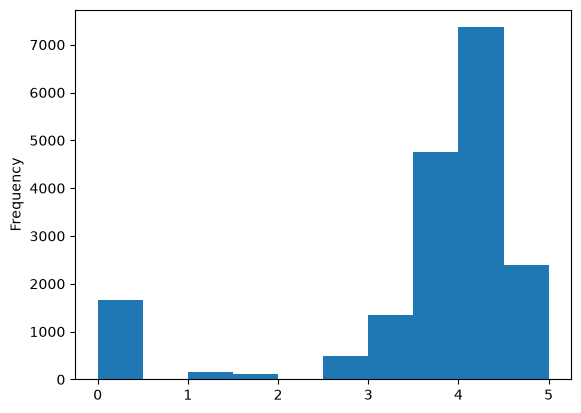

In [ ]:
y.plot.hist()

<Axes: xlabel='rating'>

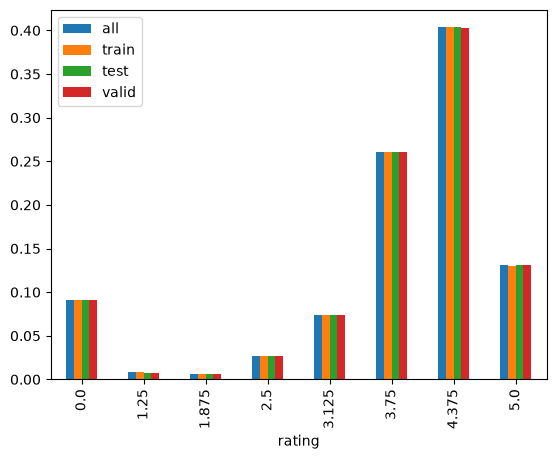

In [ ]:
def norm_value_counts(vals):
    return vals.value_counts(normalize=True).sort_index()


pd.DataFrame(
    {
        "all": norm_value_counts(y),
        "train": norm_value_counts(y_train),
        "test": norm_value_counts(y_test),
        "valid": norm_value_counts(y_valid),
    }
).plot.bar()

In [ ]:
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

### LinearRegression 

In [ ]:
log_reg = LinearRegression()

log_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](366,)","[ 0.1 , 0.48,-0.47,..., 0.4 ,-0. , 0.19]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](366,)","['almond','amaretto','anchovy',...,'yuca','zucchini','turkey']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.402
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,366
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(361)


In [ ]:
root_mean_squared_error(y_train, log_reg.predict(X_train))

1.2254438393297489

In [ ]:
cross_val_score(log_reg, X_train, y_train, scoring='neg_root_mean_squared_error', cv=cv_strategy)

array([-1.28927384, -1.32110399, -1.29587189, -1.27305179, -1.25476463])

### RandomRorest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf_clf = RandomForestRegressor(n_jobs=-1)
rf_clf.fit(X_train, y_train)
root_mean_squared_error(y_train, rf_clf.predict(X_train))

0.6136703192912166

In [ ]:
cross_val_score(rf_clf, X_train, y_train, cv=cv_strategy, n_jobs=-1, scoring='neg_root_mean_squared_error')

KeyboardInterrupt: 

In [ ]:
pd.DataFrame({'name': rf_clf.feature_names_in_, 'importance': rf_clf.feature_importances_}).sort_values(by='importance', ascending=False)

,name,importance
119,gin,0.045678
101,egg,0.014349
97,dessert,0.013766
162,lemon,0.013382
186,milk/cream,0.012955
...,...,...
363,yuca,0.000002
175,macaroni and cheese,0.000000
185,mezcal,0.000000
310,sourdough,0.000000


In [ ]:
df_epi_drop_dup[df_epi_drop_dup['gin'] == 1][['title', 'rating']]['rating']

rating
0.000    155
5.000     28
4.375     16
3.750     13
2.500      5
3.125      4
1.250      3
Name: count, dtype: int64